STEP 0 — Install / Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from scipy.stats import norm

import warnings
warnings.filterwarnings('ignore')

STEP 1 — INTRODUCTION

# Taxi Fare Prediction

Taxi Fare Prediction is a machine learning project used to predict
the fare of a taxi/cab ride using trip-related information.

In this project, we perform data cleaning, preprocessing,
descriptive statistics, exploratory data analysis, probability,
sampling and statistical estimation.

Finally, Linear Regression is used to predict the taxi fare.

STEP 2 — PROBLEM STATEMENT

## Problem Statement

To develop a machine learning model that predicts the fare of a
taxi/cab ride using available trip-related features.

The project performs statistical analysis and data preprocessing
before applying Linear Regression for fare prediction.

The model is evaluated using MAE, MSE, RMSE and R² score.

STEP 3 — DATASET COLLECTION


## Dataset Collection

Dataset Name:
Cab Fares & Surge Pricing in Cities (India)

Source:
Kaggle

The dataset contains cab/ride-related information that can be used
for studying fare patterns and building a fare prediction model.

STEP 4 — DATA LOADING

In [2]:
import os
print(os.listdir())

['.config', 'Cab_Fares.csv', 'sample_data']


In [3]:
df = pd.read_csv("Cab_Fares.csv")

In [4]:
print(df.columns.tolist())

['User_ID', 'Driver_Name', 'City', 'Ride_Date', 'Hour_of_Day', 'Day_of_Week', 'Distance_km', 'Traffic_Level', 'Type_of_vehicle', 'No_of_active_drivers', 'Ride_Requests', 'Demand_Supply_Ratio', 'Trip_Duration', 'Base_Fare', 'Surge_Multiplier', 'Final_Fare']


STEP 5 — DATA UNDERSTANDING

In [5]:
#5.1 First 5 rows
df.head()

,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare
0,USER-21819-Bcbf,Patrick Sanchez,Pune,05-11-2025,0,Friday,26.21,Low,Hatchback,36,67,1.86,60,354.52,1.3,460.88
1,USER-79402-SBvr,Meredith Barnes,Mumbai,13-10-2025,2,Friday,21.08,High,Auto,9,17,1.89,50,282.96,1.3,367.85
2,USER-40781-yfJs,Ian Cooper,Bengaluru,16-06-2026,6,Sunday,25.34,High,Hatchback,94,149,1.59,75,344.08,1.3,447.30
3,USER-41316-rDOx,Amber Perez,Mumbai,15-10-2025,0,Monday,26.80,High,Auto,25,188,7.52,76,351.60,1.6,562.56
4,USER-76483-RuXX,Kimberly Sanchez,Chennai,06-09-2025,10,Friday,4.48,High,SUV,53,34,0.64,18,133.76,1.0,133.76


In [6]:
#5.2 Shape
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 50000
Columns: 16


In [7]:
#5.3 Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               50000 non-null  object 
 1   Driver_Name           49230 non-null  object 
 2   City                  50000 non-null  object 
 3   Ride_Date             50000 non-null  object 
 4   Hour_of_Day           50000 non-null  int64  
 5   Day_of_Week           50000 non-null  object 
 6   Distance_km           50000 non-null  float64
 7   Traffic_Level         50000 non-null  object 
 8   Type_of_vehicle       50000 non-null  object 
 9   No_of_active_drivers  50000 non-null  int64  
 10  Ride_Requests         50000 non-null  int64  
 11  Demand_Supply_Ratio   50000 non-null  float64
 12  Trip_Duration         50000 non-null  int64  
 13  Base_Fare             50000 non-null  float64
 14  Surge_Multiplier      50000 non-null  float64
 15  Final_Fare         

In [8]:
#5.4 Statistical summary
df.describe()

,Hour_of_Day,Distance_km,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000
mean,11.66154,18.001724,52.243840,105.407920,3.407479,55.52666,258.691483,1.431600,370.235054
std,6.99892,9.829860,27.721115,55.223842,4.334580,28.22449,120.108685,0.356522,199.454860
min,0.00000,1.000000,5.000000,10.000000,0.100000,5.00000,27.000000,1.000000,27.000000
25%,6.00000,9.450000,28.000000,57.750000,1.100000,32.00000,155.640000,1.000000,209.477500
50%,12.00000,17.980000,52.000000,106.000000,2.020000,55.00000,259.260000,1.500000,347.490000
75%,18.00000,26.510000,76.000000,153.000000,3.780000,79.00000,360.840000,1.800000,498.345000
max,23.00000,35.000000,100.000000,200.000000,40.000000,127.00000,500.000000,2.000000,999.520000


In [9]:
#5.5 Column names
df.columns

Index(['User_ID', 'Driver_Name', 'City', 'Ride_Date', 'Hour_of_Day',
       'Day_of_Week', 'Distance_km', 'Traffic_Level', 'Type_of_vehicle',
       'No_of_active_drivers', 'Ride_Requests', 'Demand_Supply_Ratio',
       'Trip_Duration', 'Base_Fare', 'Surge_Multiplier', 'Final_Fare'],
      dtype='object')

STEP 6 — DATA CLEANING

In [10]:
#6.1 Missing values
df.isnull().sum()

,0
User_ID,0
Driver_Name,770
City,0
Ride_Date,0
Hour_of_Day,0
Day_of_Week,0
Distance_km,0
Traffic_Level,0
Type_of_vehicle,0
No_of_active_drivers,0


In [11]:
df = df.dropna()

In [12]:
df.isnull().sum()

,0
User_ID,0
Driver_Name,0
City,0
Ride_Date,0
Hour_of_Day,0
Day_of_Week,0
Distance_km,0
Traffic_Level,0
Type_of_vehicle,0
No_of_active_drivers,0


In [13]:
#6.2 Duplicate values
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
df = df.drop_duplicates()

In [15]:
#6.3 Data types
df.dtypes

,0
User_ID,object
Driver_Name,object
City,object
Ride_Date,object
Hour_of_Day,int64
Day_of_Week,object
Distance_km,float64
Traffic_Level,object
Type_of_vehicle,object
No_of_active_drivers,int64


In [16]:
#6.4 Numerical columns
df.select_dtypes(include=np.number).columns

Index(['Hour_of_Day', 'Distance_km', 'No_of_active_drivers', 'Ride_Requests',
       'Demand_Supply_Ratio', 'Trip_Duration', 'Base_Fare', 'Surge_Multiplier',
       'Final_Fare'],
      dtype='object')

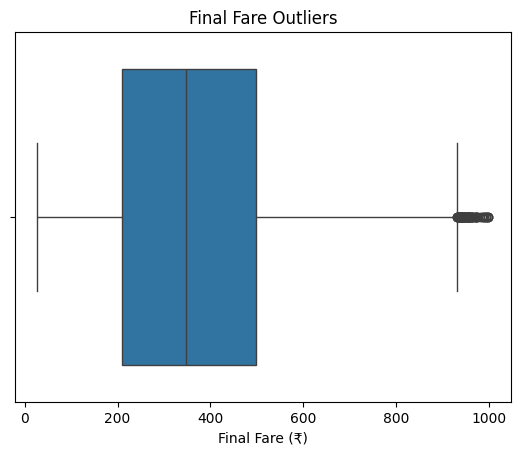

In [17]:
#6.5 Outliers
sns.boxplot(x=df['Final_Fare'])

plt.title("Final Fare Outliers")
plt.xlabel("Final Fare (₹)")

plt.show()

In [18]:
df['Final_Fare'].describe()

,Final_Fare
count,49230.000000
mean,370.429427
std,199.504925
min,27.000000
25%,209.640000
50%,347.840000
75%,498.435000
max,999.520000


In [19]:
df = df[df['Final_Fare'] > 0]  #Remove obvious invalid fares

In [20]:
y = df['Final_Fare']

 STEP 7 — DATA PREPROCESSING

In [21]:
df.columns.tolist()

['User_ID',
 'Driver_Name',
 'City',
 'Ride_Date',
 'Hour_of_Day',
 'Day_of_Week',
 'Distance_km',
 'Traffic_Level',
 'Type_of_vehicle',
 'No_of_active_drivers',
 'Ride_Requests',
 'Demand_Supply_Ratio',
 'Trip_Duration',
 'Base_Fare',
 'Surge_Multiplier',
 'Final_Fare']

In [22]:
#Convert date/time if available
df['Ride_Date'] = pd.to_datetime(df['Ride_Date'], format='%d-%m-%Y')


df['hour'] = df['Ride_Date'].dt.hour
df['day'] = df['Ride_Date'].dt.day
df['month'] = df['Ride_Date'].dt.month
df['weekday'] = df['Ride_Date'].dt.weekday

STEP 8 — DESCRIPTIVE STATISTICS

In [23]:
df['Final_Fare'].mean()    #Mean

np.float64(370.42942738167784)

In [24]:
df['Final_Fare'].median()

347.84

In [25]:
df['Final_Fare'].mode()[0] #Mode

np.float64(351.12)

In [26]:
df['Final_Fare'].var()#Variance

39802.21507105873

In [27]:
df['Final_Fare'].std()#Standard deviation

199.50492492933284

In [28]:
df['Final_Fare'].quantile([0.25, 0.50, 0.75])#Quartiles

,Final_Fare
0.25,209.640
0.50,347.840
0.75,498.435


In [29]:
df['Final_Fare'].describe()

,Final_Fare
count,49230.000000
mean,370.429427
std,199.504925
min,27.000000
25%,209.640000
50%,347.840000
75%,498.435000
max,999.520000


STEP 9 — EXPLORATORY DATA ANALYSIS

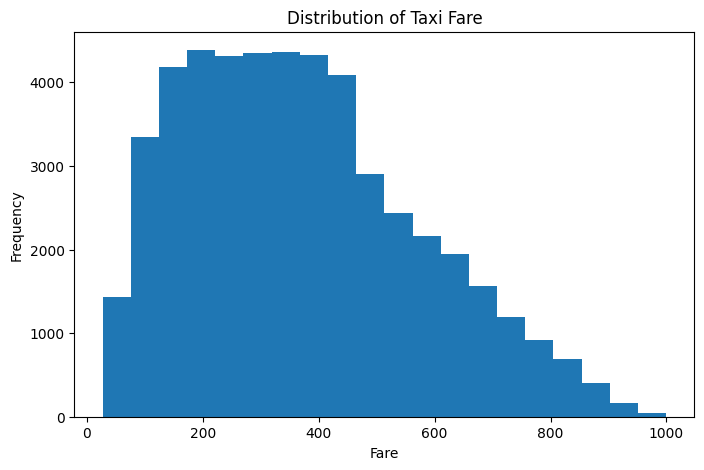

In [30]:
#9.1 Histogram
plt.figure(figsize=(8,5))

plt.hist(df['Final_Fare'], bins=20)

plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.title("Distribution of Taxi Fare")

plt.show()

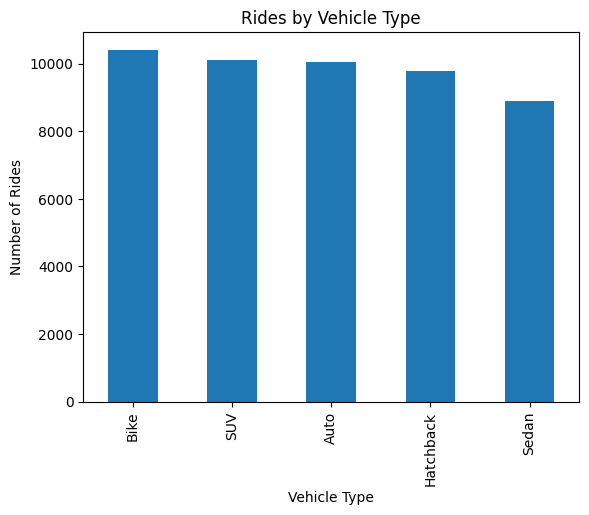

In [31]:
#9.2 Bar Chart
df['Type_of_vehicle'].value_counts().plot(kind='bar')

plt.xlabel("Vehicle Type")
plt.ylabel("Number of Rides")
plt.title("Rides by Vehicle Type")

plt.show()

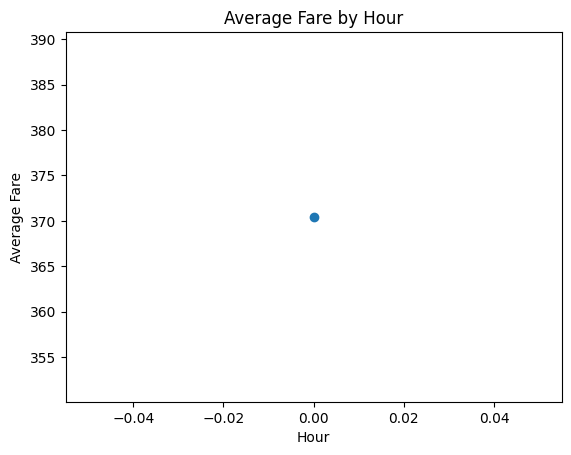

In [32]:
#9.3 Line Chart
hourly_fare = df.groupby('hour')['Final_Fare'].mean()

plt.plot(hourly_fare.index, hourly_fare.values, marker='o')

plt.xlabel("Hour")
plt.ylabel("Average Fare")
plt.title("Average Fare by Hour")

plt.show()

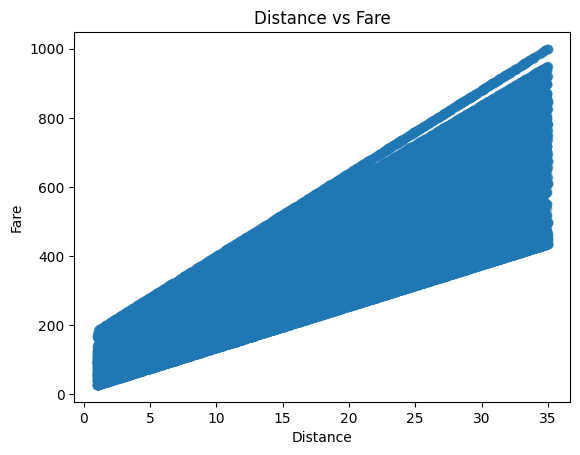

In [33]:
#9.4 Scatter Plot
plt.scatter(
    df['Distance_km'],
    df['Final_Fare'],
    alpha=0.5
)

plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Distance vs Fare")

plt.show()

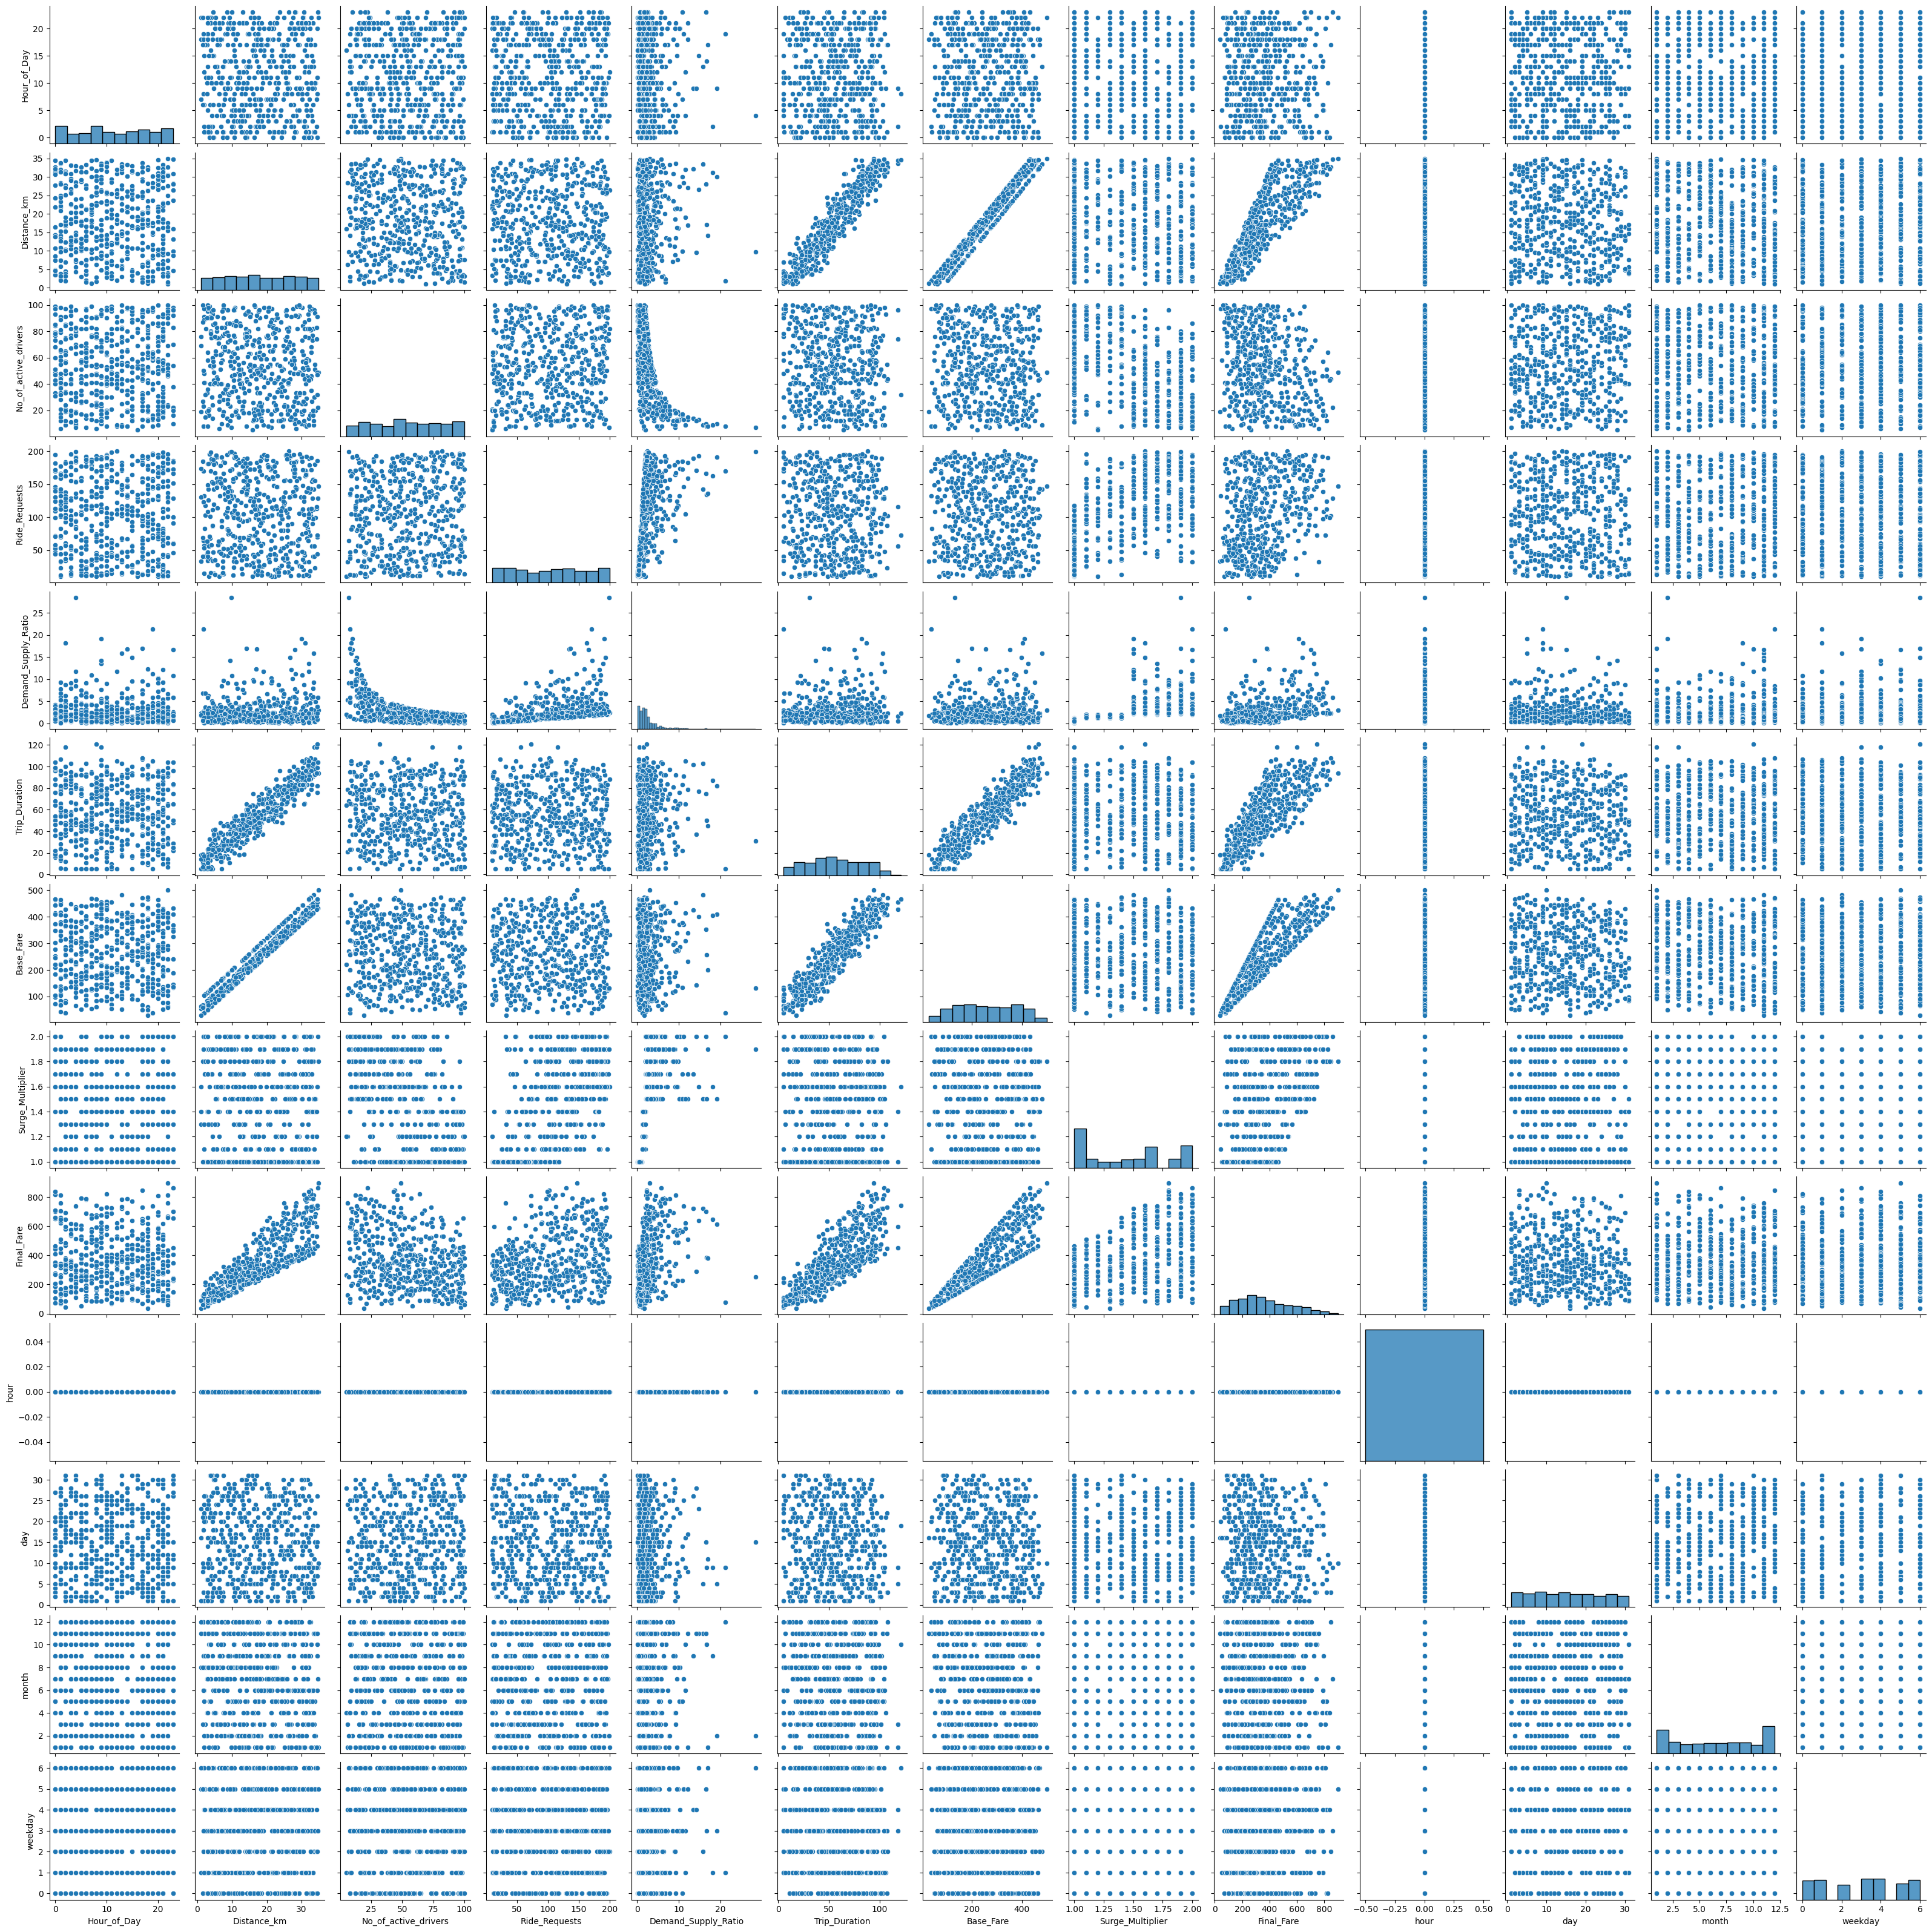

In [34]:
#9.5 Pair Plot
numeric_df = df.select_dtypes(include=np.number)

sns.pairplot(
    numeric_df.sample(min(500, len(numeric_df)),
                      random_state=42)
)
plt.show()

#This version is safer because it automatically uses numerical columns.

STEP 10 — PROBABILITY DISTRIBUTIONS

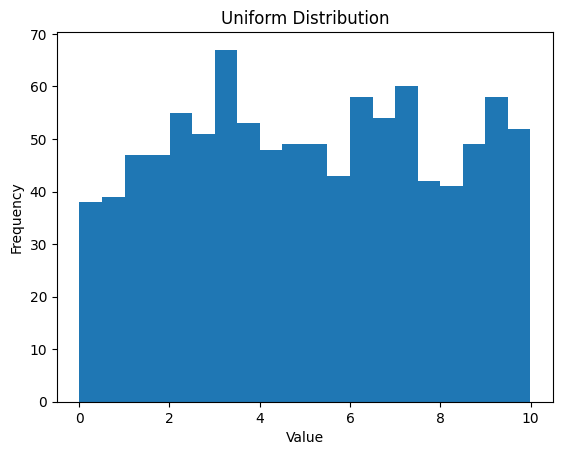

In [35]:
#10.1 Uniform Distribution
uniform_data = np.random.uniform(0, 10, 1000)

plt.hist(uniform_data, bins=20)

plt.title("Uniform Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.show()

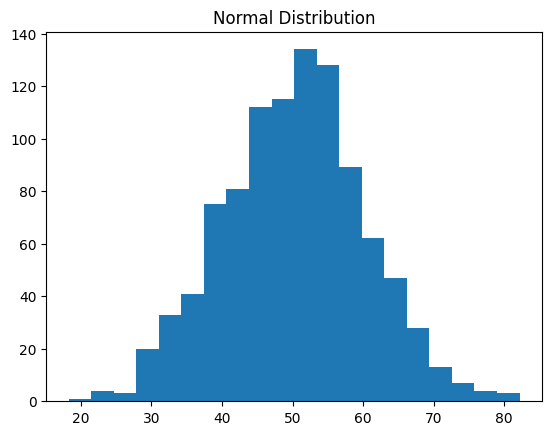

In [36]:
#10.2 Normal Distribution
normal_data = np.random.normal(50, 10, 1000)

plt.hist(normal_data, bins=20)

plt.title("Normal Distribution")

plt.show()

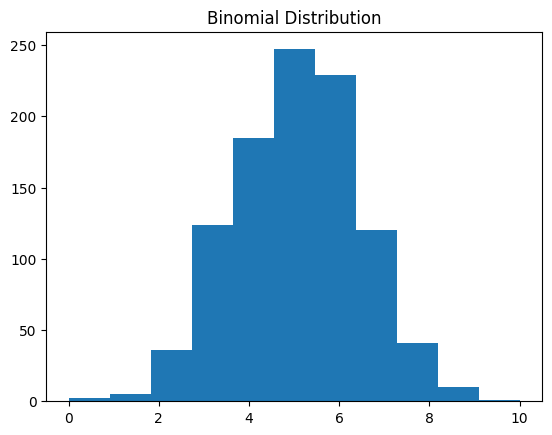

In [37]:
#10.3 Binomial Distribution
binomial_data = np.random.binomial(
    n=10,
    p=0.5,
    size=1000
)

plt.hist(binomial_data, bins=11)

plt.title("Binomial Distribution")

plt.show()

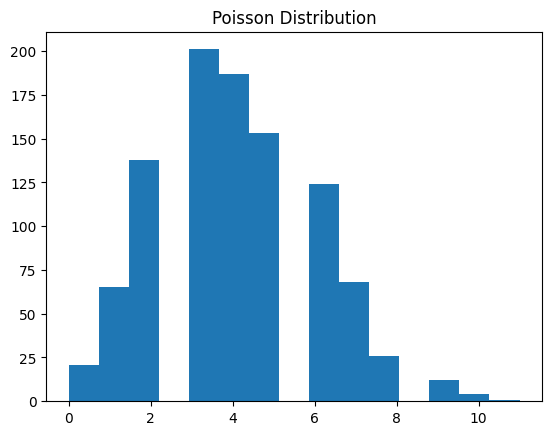

In [38]:
#10.4 Poisson Distribution
poisson_data = np.random.poisson(
    lam=4,
    size=1000
)

plt.hist(poisson_data, bins=15)

plt.title("Poisson Distribution")

plt.show()

STEP 11 — SAMPLING

In [39]:
#11.1 Simple Random Sampling
random_sample = df.sample(
    n=min(100, len(df)),
    random_state=42
)

random_sample.head()


,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare,hour,day,month,weekday
28810,USER-22860-HtHk,Patrick Odom,Delhi,2025-11-06,7,Thursday,24.71,Medium,SUV,13,80,6.15,74,376.52,1.8,677.74,0,6,11,3
14078,USER-25247-pSGD,Darryl Santos,Mumbai,2026-07-05,16,Sunday,16.05,Jam,SUV,69,31,0.45,75,272.60,1.0,272.60,0,5,7,6
12548,USER-76742-yhHS,Nicolas Barry,Mumbai,2026-01-16,2,Friday,17.40,Low,Sedan,19,34,1.79,56,258.80,1.1,284.68,0,16,1,4
47809,USER-13320-VXhS,Donna Jacobs,Hyderabad,2026-01-09,20,Friday,30.41,Medium,Auto,84,148,1.76,81,394.92,1.1,434.41,0,9,1,4
48632,USER-04735-NxQq,Gregory Lambert,Bengaluru,2026-06-15,1,Monday,7.47,Jam,SUV,28,166,5.93,28,169.64,1.9,322.32,0,15,6,0


In [40]:
#11.2 With Replacement
with_replacement = df.sample(
    n=100,
    replace=True,
    random_state=42
)

with_replacement.head()

,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare,hour,day,month,weekday
16041,USER-60960-iInf,Phillip Gibbs,Mumbai,2026-07-07,7,Tuesday,4.10,Low,SUV,28,69,2.46,9,129.20,2.0,258.40,0,7,7,1
874,USER-94097-BTWi,Ana Higgins,Bengaluru,2026-08-12,5,Wednesday,10.80,Jam,Sedan,14,37,2.64,27,179.60,1.8,323.28,0,12,8,2
38772,USER-61097-deOi,Kristine Bray,Bengaluru,2026-05-07,1,Thursday,6.99,High,Auto,23,87,3.78,26,113.88,1.9,216.37,0,7,5,3
45445,USER-36171-EiIa,Jeanne Wheeler,Pune,2026-05-15,11,Friday,34.88,Low,SUV,28,188,6.71,125,498.56,1.8,897.41,0,15,5,4
11447,USER-64622-dMzR,Crystal Floyd,Chennai,2025-08-23,5,Saturday,22.50,High,SUV,59,80,1.36,47,350.00,1.4,490.00,0,23,8,5


In [41]:
#11.3 Without Replacement
without_replacement = df.sample(
    n=min(100, len(df)),
    replace=False,
    random_state=42
)

without_replacement.head()

,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare,hour,day,month,weekday
28810,USER-22860-HtHk,Patrick Odom,Delhi,2025-11-06,7,Thursday,24.71,Medium,SUV,13,80,6.15,74,376.52,1.8,677.74,0,6,11,3
14078,USER-25247-pSGD,Darryl Santos,Mumbai,2026-07-05,16,Sunday,16.05,Jam,SUV,69,31,0.45,75,272.60,1.0,272.60,0,5,7,6
12548,USER-76742-yhHS,Nicolas Barry,Mumbai,2026-01-16,2,Friday,17.40,Low,Sedan,19,34,1.79,56,258.80,1.1,284.68,0,16,1,4
47809,USER-13320-VXhS,Donna Jacobs,Hyderabad,2026-01-09,20,Friday,30.41,Medium,Auto,84,148,1.76,81,394.92,1.1,434.41,0,9,1,4
48632,USER-04735-NxQq,Gregory Lambert,Bengaluru,2026-06-15,1,Monday,7.47,Jam,SUV,28,166,5.93,28,169.64,1.9,322.32,0,15,6,0


In [42]:
#11.4 Systematic Sampling
step = 10

systematic_sample = df.iloc[::step]

systematic_sample.head()


,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare,hour,day,month,weekday
0,USER-21819-Bcbf,Patrick Sanchez,Pune,2025-11-05,0,Friday,26.21,Low,Hatchback,36,67,1.86,60,354.52,1.3,460.88,0,5,11,2
10,USER-96383-TtzQ,Joshua Baker,Pune,2026-04-11,1,Sunday,8.79,Jam,Auto,9,90,10.00,25,135.48,1.6,216.77,0,11,4,5
21,USER-24278-TBJa,Donald Smith,Pune,2025-09-27,5,Saturday,10.01,Medium,Hatchback,82,118,1.44,44,160.12,1.3,208.16,0,27,9,5
31,USER-83172-ZDQH,Melissa Marshall,Mumbai,2026-08-13,1,Saturday,6.60,Jam,Hatchback,5,109,21.80,24,119.20,1.6,190.72,0,13,8,3
41,USER-87769-rupf,Tracie Nelson,Mumbai,2025-11-27,4,Wednesday,9.99,Jam,Hatchback,18,200,11.11,34,159.88,1.6,255.81,0,27,11,3


In [43]:
#11.5 Stratified Sampling
df['fare_group'] = pd.qcut(
    df['Final_Fare'],
    q=3,
    labels=['Low', 'Medium', 'High'],
    duplicates='drop'
)

In [44]:
stratified_sample = (
    df.groupby('fare_group', observed=True)
      .sample(n=min(30, df['fare_group'].value_counts().min()),
              random_state=42)
)

stratified_sample.head()

,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,...,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare,hour,day,month,weekday,fare_group
45294,USER-61515-UfnH,Ashley Wallace,Chennai,2026-07-22,19,Wednesday,3.71,High,SUV,56,...,3.09,5,124.52,1.5,186.78,0,22,7,2,Low
38231,USER-50320-IZvB,Austin Garrett,Hyderabad,2026-05-17,14,Sunday,7.79,Medium,Bike,56,...,0.93,13,108.48,1.0,108.48,0,17,5,6,Low
12485,USER-10109-EDAA,Jasmin Adams,Chennai,2026-04-25,0,Saturday,2.96,Jam,Bike,15,...,0.93,15,50.52,1.0,50.52,0,25,4,5,Low
14406,USER-83459-Exii,Elizabeth Andrade,Pune,2026-01-15,22,Thursday,13.60,Jam,Auto,94,...,0.79,34,193.20,1.0,193.20,0,15,1,3,Low
446,USER-85880-WcBh,Jonathan Wagner,Mumbai,2026-01-04,18,Saturday,2.10,Jam,SUV,82,...,1.11,12,105.20,1.0,105.20,0,4,1,6,Low


In [45]:
#11.6 Cluster Sampling
df['City'].value_counts()

,count
City,
Pune,9440
Chennai,8443
Delhi,8226
Mumbai,7845
Bengaluru,7663
Hyderabad,7613


In [46]:
cluster_sample = df[
    df['City'] == df['City'].iloc[0]
]

STEP 12 — POPULATION VS SAMPLE

In [47]:
population = df['Final_Fare']

sample = df['Final_Fare'].sample(
    n=min(100, len(df)),
    random_state=42
)

print("Population Size:", len(population))
print("Sample Size:", len(sample))

print("Population Mean:", population.mean())
print("Sample Mean:", sample.mean())


#Population = Complete set of observations.

#Sample = Smaller subset selected from the population.

Population Size: 49230
Sample Size: 100
Population Mean: 370.42942738167784
Sample Mean: 392.2525


STEP 13 — CENTRAL LIMIT THEOREM

In [48]:
#Take 100 sample
sample_means = []

sample_size = min(30, len(df))

for i in range(100):

    sample = df['Final_Fare'].sample(
        n=sample_size,
        random_state=i
    )

    sample_means.append(sample.mean())

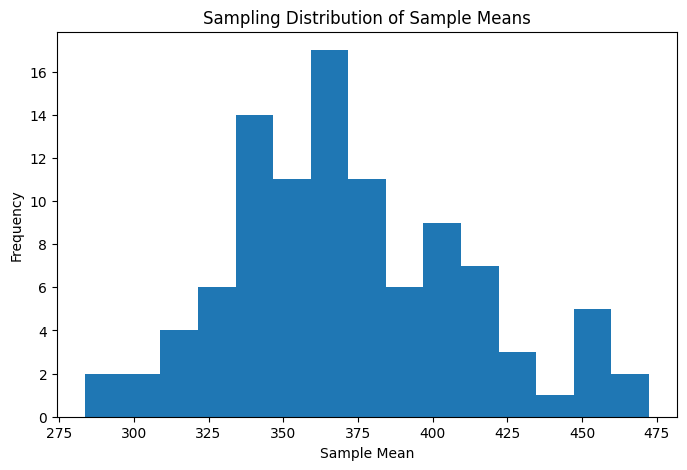

In [49]:
plt.figure(figsize=(8,5))

plt.hist(sample_means, bins=15)

plt.xlabel("Sample Mean")
plt.ylabel("Frequency")

plt.title("Sampling Distribution of Sample Means")

plt.show()

In [50]:
print(
    "Population Mean:",
    df['Final_Fare'].mean()
)

print(
    "Mean of Sample Means:",
    np.mean(sample_means)
)

#Central Limit Theorem states that the distribution of sample means tends to become approximately normal when repeated random samples are taken from a population.

Population Mean: 370.42942738167784
Mean of Sample Means: 372.73112999999995


STEP 14 — STANDARD ERROR

SE = Standard Deviation / √n

In [51]:
sample = df['Final_Fare'].sample(
    n=min(100, len(df)),
    random_state=42
)

se = sample.std() / np.sqrt(len(sample))

print("Standard Error:", se)

Standard Error: 20.66576506409437


STEP 15 — POINT ESTIMATION

In [52]:
sample = df['Final_Fare'].sample(
    n=min(100, len(df)),
    random_state=42
)

point_estimate = sample.mean()

print("Point Estimate:", point_estimate)
#Sample mean is used as an estimate of the population mean.

Point Estimate: 392.2525


STEP 16 — CONFIDENCE INTERVAL

In [53]:
#95% confidence interval:
sample = df['Final_Fare'].sample(
    n=min(100, len(df)),
    random_state=42
)

mean = sample.mean()

se = sample.std() / np.sqrt(len(sample))

margin = norm.ppf(0.975) * se

lower = mean - margin
upper = mean + margin

print("Sample Mean:", mean)

print("95% Confidence Interval:")
print(lower, "to", upper)

Sample Mean: 392.2525
95% Confidence Interval:
351.74834476140893 to 432.75665523859107


STEP 17 — FEATURE SELECTION

In [54]:
df.select_dtypes(include=np.number).columns.tolist()

['Hour_of_Day',
 'Distance_km',
 'No_of_active_drivers',
 'Ride_Requests',
 'Demand_Supply_Ratio',
 'Trip_Duration',
 'Base_Fare',
 'Surge_Multiplier',
 'Final_Fare',
 'hour',
 'day',
 'month',
 'weekday']

In [55]:
features = [
    'Distance_km',
    'Trip_Duration',
    'Surge_Multiplier'
]

X = df[features]

y = df['Final_Fare']

In [56]:
X.head()

,Distance_km,Trip_Duration,Surge_Multiplier
0,26.21,60,1.3
1,21.08,50,1.3
2,25.34,75,1.3
3,26.80,76,1.6
4,4.48,18,1.0


In [57]:
y.head()

,Final_Fare
0,460.88
1,367.85
2,447.30
3,562.56
4,133.76


In [58]:
print(df.columns.tolist())

['User_ID', 'Driver_Name', 'City', 'Ride_Date', 'Hour_of_Day', 'Day_of_Week', 'Distance_km', 'Traffic_Level', 'Type_of_vehicle', 'No_of_active_drivers', 'Ride_Requests', 'Demand_Supply_Ratio', 'Trip_Duration', 'Base_Fare', 'Surge_Multiplier', 'Final_Fare', 'hour', 'day', 'month', 'weekday', 'fare_group']


STEP 18 — TRAIN-TEST SPLIT

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [60]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (39384, 3)
Testing data: (9846, 3)


STEP 19 — LINEAR REGRESSION

In [61]:
model = LinearRegression()

In [62]:
model.fit(X_train, y_train)

LinearRegression()

In [63]:
print("Intercept:", model.intercept_)

print("Coefficients:")

for feature, coefficient in zip(features, model.coef_):
    print(feature, ":", coefficient)

Intercept: -309.6653752044093
Coefficients:
Distance_km : 17.161606902865913
Trip_Duration : -0.004692396613851416
Surge_Multiplier : 259.24388207014385


STEP 20 — FARE PREDICTION

In [64]:
y_pred = model.predict(X_test)

In [65]:
prediction_df = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred
})

prediction_df.head(10)

,Actual Fare,Predicted Fare
0,677.74,580.689682
1,272.60,224.670368
2,284.68,273.852081
3,434.41,497.007277
4,322.32,310.963817
5,69.38,102.649871
6,166.80,306.573162
7,585.20,508.663526
8,686.10,661.367763
9,206.06,277.617706


In [66]:
#Predict a new ride
new_ride = pd.DataFrame({
    'Distance_km': [5],
    'Trip_Duration': [20],
    'Surge_Multiplier': [1]
})

In [67]:
predicted_fare = model.predict(new_ride)

print(
    "Predicted Taxi Fare: ₹",
    round(predicted_fare[0], 2)
)

Predicted Taxi Fare: ₹ 35.29


STEP 21 — MODEL EVALUATION

In [68]:
#MAE
mae = mean_absolute_error(
    y_test,
    y_pred
)

print("MAE:", mae)

MAE: 42.13264597645529


In [69]:
#MSE
mse = mean_squared_error(
    y_test,
    y_pred
)

print("MSE:", mse)

MSE: 2805.523495548806


In [70]:
#RMSE
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 52.96719263420335


In [71]:
#R²
r2 = r2_score(
    y_test,
    y_pred
)

print("R² Score:", r2)

R² Score: 0.930181127916049


In [72]:
#All metrics together
print("----- MODEL EVALUATION -----")

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

----- MODEL EVALUATION -----
MAE : 42.13264597645529
MSE : 2805.523495548806
RMSE: 52.96719263420335
R²  : 0.930181127916049


STEP 22 — CONCLUSION

## Conclusion

In this project, Indian cab fare data was collected from Kaggle
and analyzed using Python.

The dataset was first understood using head(), shape(), info()
and describe().

Data cleaning was performed by handling missing values, duplicate
records, incorrect data types and outliers.

Data preprocessing was then performed to prepare the data for
statistical analysis and machine learning.

Descriptive statistics including mean, median, mode, variance,
standard deviation and quartiles were calculated.

Exploratory Data Analysis was performed using histograms, bar
charts, line charts, scatter plots and pair plots.

Probability distributions and different sampling techniques were
also demonstrated.

Population and sample concepts, Central Limit Theorem, Standard
Error, Point Estimation and Confidence Interval were implemented.

Finally, Linear Regression was used to predict taxi fare.

The model was evaluated using MAE, MSE, RMSE and R² score.

Thus, the project demonstrates the complete journey from data
collection and statistical analysis to machine learning based
Indian taxi fare prediction.

STEP 23: CORRELATION ANALYSIS

Correlation Matrix:


,Hour_of_Day,Distance_km,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare,hour,day,month,weekday
Hour_of_Day,1.0,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,NaN,0.00,0.00,0.00
Distance_km,-0.0,1.00,0.01,0.00,-0.00,0.95,0.98,-0.00,0.85,NaN,0.00,-0.00,0.00
No_of_active_drivers,-0.0,0.01,1.00,-0.00,-0.60,0.01,0.01,-0.53,-0.24,NaN,-0.00,0.00,0.00
Ride_Requests,-0.0,0.00,-0.00,1.00,0.41,0.01,0.00,0.61,0.29,NaN,-0.00,-0.00,0.00
Demand_Supply_Ratio,0.0,-0.00,-0.60,0.41,1.00,-0.00,-0.00,0.50,0.23,NaN,-0.00,-0.00,-0.00
Trip_Duration,0.0,0.95,0.01,0.01,-0.00,1.00,0.93,-0.00,0.80,NaN,0.00,-0.00,0.00
Base_Fare,-0.0,0.98,0.01,0.00,-0.00,0.93,1.00,-0.00,0.86,NaN,0.00,-0.00,0.00
Surge_Multiplier,-0.0,-0.00,-0.53,0.61,0.50,-0.00,-0.00,1.00,0.46,NaN,0.00,-0.00,0.00
Final_Fare,-0.0,0.85,-0.24,0.29,0.23,0.80,0.86,0.46,1.00,NaN,0.00,-0.01,0.00
hour,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


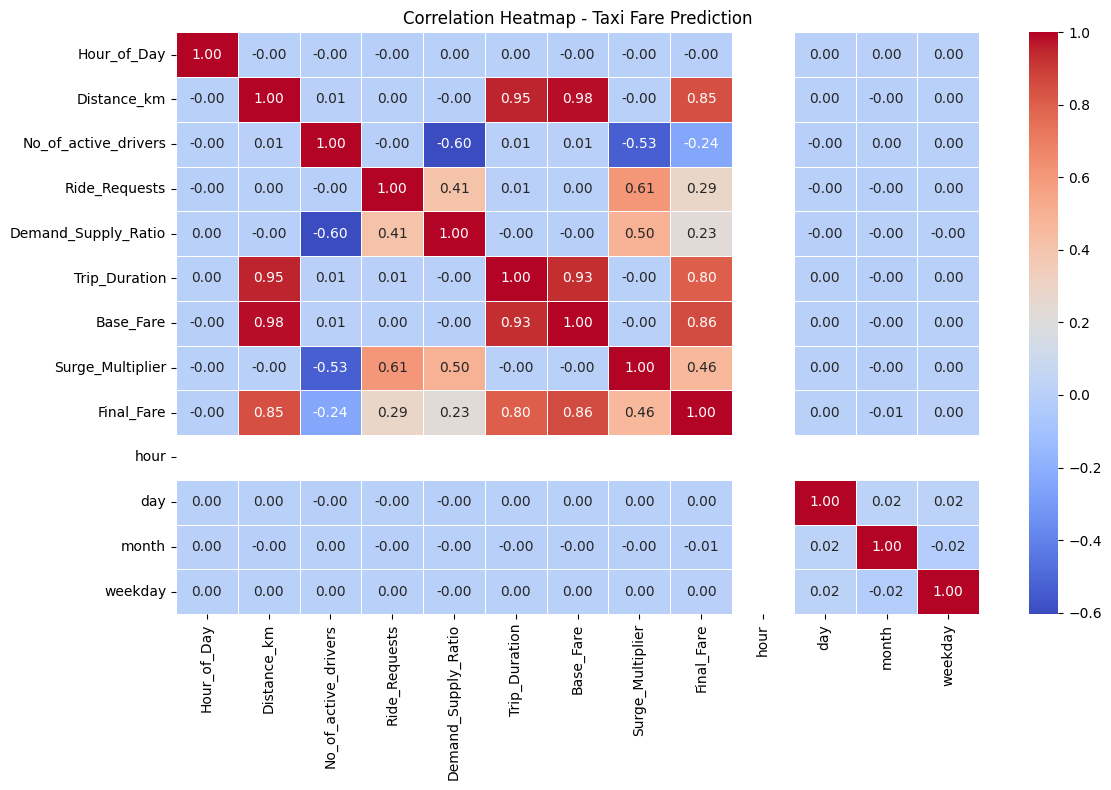

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_df = df.select_dtypes(include=['number'])

# Display correlation matrix
correlation_matrix = numerical_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Visualize correlations
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - Taxi Fare Prediction")
plt.tight_layout()
plt.show()

Step 24 — Hypothesis Testing (One-Sample t-Test)

In [74]:
# STEP 24: ONE-SAMPLE T-TEST

from scipy.stats import ttest_1samp

# Calculate the average taxi fare
mean_fare = df['Final_Fare'].mean()

print("Average Taxi Fare:", round(mean_fare, 2))

# Set the hypothesized population mean
hypothesized_mean = 300

# Perform one-sample t-test
t_statistic, p_value = ttest_1samp(
    df['Final_Fare'],
    popmean=hypothesized_mean
)

print("T-statistic:", round(t_statistic, 4))
print("P-value:", p_value)

# Interpret the result
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis (H0).")
    print("The average taxi fare differs significantly from ₹300.")
else:
    print("Fail to reject the null hypothesis (H0).")
    print("There is insufficient evidence that the average taxi fare differs from ₹300.")

Average Taxi Fare: 370.43
T-statistic: 78.3277
P-value: 0.0
Reject the null hypothesis (H0).
The average taxi fare differs significantly from ₹300.


Step 25 — Independent Samples t-Test

In [75]:
# STEP 25: INDEPENDENT SAMPLES T-TEST

from scipy.stats import ttest_ind

# Divide rides into low-surge and high-surge groups
low_surge = df[df['Surge_Multiplier'] <= 1.5]['Final_Fare']
high_surge = df[df['Surge_Multiplier'] > 1.5]['Final_Fare']

# Display group averages
print("Low-Surge Rides:")
print("Number of rides:", len(low_surge))
print("Average fare: ₹", round(low_surge.mean(), 2))

print("\nHigh-Surge Rides:")
print("Number of rides:", len(high_surge))
print("Average fare: ₹", round(high_surge.mean(), 2))

# Perform Welch's independent samples t-test
t_statistic, p_value = ttest_ind(
    low_surge,
    high_surge,
    equal_var=False
)

print("\nT-statistic:", round(t_statistic, 4))
print("P-value:", p_value)

# Interpret the result
if p_value < 0.05:
    print("\nReject H0: The group means differ significantly.")
else:
    print("\nFail to reject H0: Insufficient evidence of a difference.")

Low-Surge Rides:
Number of rides: 28532
Average fare: ₹ 301.7

High-Surge Rides:
Number of rides: 20698
Average fare: ₹ 465.17

T-statistic: -92.6675
P-value: 0.0

Reject H0: The group means differ significantly.


Step 26 — Paired Samples t-Test

In [76]:
# STEP 26: ONE-WAY ANOVA - FARE DIFFERENCES ACROSS CITIES

from scipy.stats import f_oneway

# Identify cities with at least two observations
city_groups = [
    group['Final_Fare'].dropna()
    for city, group in df.groupby('City')
    if group['Final_Fare'].count() >= 2
]

# Display average fare for each city
print("Average Fare by City:")
display(df.groupby('City')['Final_Fare'].agg(['count', 'mean']).round(2))

# Perform one-way ANOVA
f_statistic, p_value = f_oneway(*city_groups)

print("\nF-statistic:", round(f_statistic, 4))
print("P-value:", p_value)

# Interpret results
if p_value < 0.05:
    print("\nReject H0: At least one city has a significantly different mean fare.")
else:
    print("\nFail to reject H0: Insufficient evidence of differences in mean fares.")

Average Fare by City:


,count,mean
City,,
Bengaluru,7663,371.41
Chennai,8443,369.13
Delhi,8226,374.09
Hyderabad,7613,372.20
Mumbai,7845,368.94
Pune,9440,367.42



F-statistic: 1.2985
P-value: 0.2612384066667511

Fail to reject H0: Insufficient evidence of differences in mean fares.


Step 27 — Chi-Square Test of Independence

In [77]:
# STEP 27: CHI-SQUARE TEST OF INDEPENDENCE

import pandas as pd
from scipy.stats import chi2_contingency

# Create a contingency table
contingency_table = pd.crosstab(
    df['City'],
    df['Traffic_Level']
)

print("Contingency Table: City vs Traffic Level")
display(contingency_table)

# Perform the chi-square test
chi2_statistic, p_value, degrees_of_freedom, expected = (
    chi2_contingency(contingency_table)
)

print("\nChi-square statistic:", round(chi2_statistic, 4))
print("Degrees of freedom:", degrees_of_freedom)
print("P-value:", p_value)

# Interpret the result
if p_value < 0.05:
    print("\nReject H0: City and traffic level are significantly associated.")
else:
    print("\nFail to reject H0: Insufficient evidence of an association.")

Contingency Table: City vs Traffic Level


Traffic_Level,High,Jam,Low,Medium
City,,,,
Bengaluru,1871,2115,1945,1732
Chennai,2123,2255,2091,1974
Delhi,2015,2208,2112,1891
Hyderabad,1876,2156,1862,1719
Mumbai,2067,2055,1921,1802
Pune,2304,2578,2354,2204



Chi-square statistic: 23.1973
Degrees of freedom: 15
P-value: 0.08004009371325282

Fail to reject H0: Insufficient evidence of an association.


Step 28 — Compare Fare Across Traffic Levels

Average Fare by Traffic Level:


,Final_Fare
Traffic_Level,
Jam,369.48
Medium,369.81
Low,369.85
High,372.62


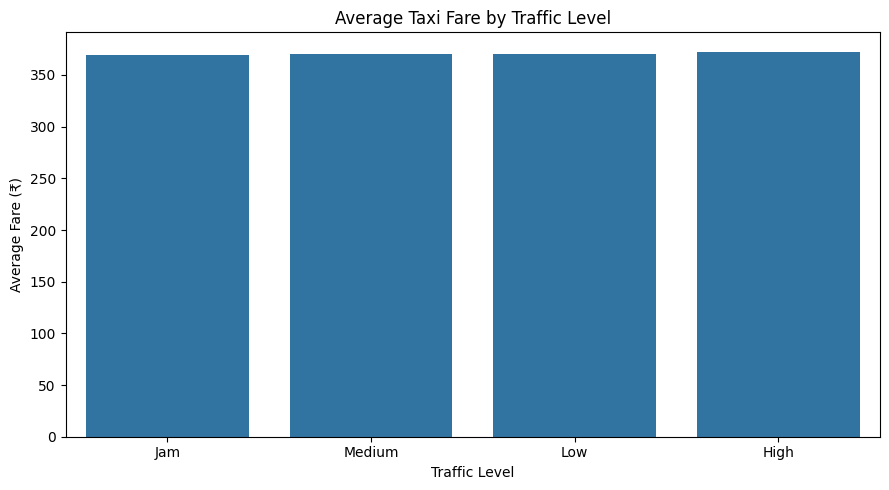

In [78]:
# STEP 28: AVERAGE FARE BY TRAFFIC LEVEL

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average fare for each traffic level
traffic_fare = df.groupby('Traffic_Level')['Final_Fare'].mean().sort_values()

print("Average Fare by Traffic Level:")
display(traffic_fare.round(2))

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x=traffic_fare.index,
    y=traffic_fare.values
)

plt.title("Average Taxi Fare by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Fare (₹)")
plt.tight_layout()
plt.show()

Step 29 — Improve Your Linear Regression Model

In [79]:
# STEP 29: IMPROVED LINEAR REGRESSION MODEL

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select features, including Base_Fare
features = [
    'Distance_km',
    'Trip_Duration',
    'Surge_Multiplier',
    'Base_Fare'
]

X = df[features]
y = df['Final_Fare']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train improved model
improved_model = LinearRegression()
improved_model.fit(X_train, y_train)

# Make predictions
y_pred = improved_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Improved Linear Regression Results")
print("----------------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Improved Linear Regression Results
----------------------------------
MAE: 32.82
MSE: 1814.67
RMSE: 42.6
R2 Score: 0.9548


Step 30 — Train and Compare Multiple Regression Models

In [80]:
# STEP 30: COMPARISON OF REGRESSION MODELS

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Features and target
features = [
    'Distance_km',
    'Trip_Duration',
    'Surge_Multiplier',
    'Base_Fare'
]

X = df[features]
y = df['Final_Fare']

# Use the same train/test split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
    )
}

results = []

# Train and evaluate each model
for name, regressor in models.items():
    regressor.fit(X_train, y_train)
    predictions = regressor.predict(X_test)

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'MSE': mean_squared_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

# Display comparison
results_df = pd.DataFrame(results).sort_values(
    by='R2 Score', ascending=False
)

print("Regression Model Comparison:")
display(results_df.round(4))

Regression Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
4,Random Forest,0.5339,0.7232,0.8504,1.0000
3,Decision Tree,1.9832,6.9555,2.6373,0.9998
1,Ridge Regression,32.8174,1814.6640,42.5989,0.9548
0,Linear Regression,32.8173,1814.6655,42.5989,0.9548
2,Lasso Regression,32.8187,1814.7096,42.5994,0.9548


Step 31 — Check the fare calculation

In [81]:
# STEP 31: INVESTIGATE THE FARE CALCULATION

print("Dataset shape:", df.shape)

print("\nFirst 10 rides:")
display(
    df[
        [
            'Distance_km',
            'Trip_Duration',
            'Surge_Multiplier',
            'Base_Fare',
            'Final_Fare'
        ]
    ].head(10)
)

print("\nCorrelation with Final_Fare:")
display(
    df[
        [
            'Distance_km',
            'Trip_Duration',
            'Surge_Multiplier',
            'Base_Fare',
            'Final_Fare'
        ]
    ].corr().round(4)
)

Dataset shape: (49230, 21)

First 10 rides:


,Distance_km,Trip_Duration,Surge_Multiplier,Base_Fare,Final_Fare
0,26.21,60,1.3,354.52,460.88
1,21.08,50,1.3,282.96,367.85
2,25.34,75,1.3,344.08,447.30
3,26.80,76,1.6,351.60,562.56
4,4.48,18,1.0,133.76,133.76
5,25.81,97,1.0,349.72,349.72
6,29.20,86,1.1,390.40,429.44
7,34.50,97,1.0,454.00,454.00
8,6.53,22,1.3,158.36,205.87
9,9.32,32,1.2,126.84,152.21



Correlation with Final_Fare:


,Distance_km,Trip_Duration,Surge_Multiplier,Base_Fare,Final_Fare
Distance_km,1.0000,0.9505,-0.0018,0.9828,0.8455
Trip_Duration,0.9505,1.0000,-0.0004,0.9343,0.8044
Surge_Multiplier,-0.0018,-0.0004,1.0000,-0.0023,0.4612
Base_Fare,0.9828,0.9343,-0.0023,1.0000,0.8599
Final_Fare,0.8455,0.8044,0.4612,0.8599,1.0000


Step 32 — Verify the fare formula

In [82]:
# STEP 32: CHECK WHETHER FINAL FARE FOLLOWS A FORMULA

df['Calculated_Fare'] = (
    df['Base_Fare'] * df['Surge_Multiplier']
)

df['Fare_Difference'] = (
    df['Final_Fare'] - df['Calculated_Fare']
).abs()

print("First 10 fare comparisons:")

display(
    df[
        [
            'Base_Fare',
            'Surge_Multiplier',
            'Final_Fare',
            'Calculated_Fare',
            'Fare_Difference'
        ]
    ].head(10).round(2)
)

print("\nFare difference statistics:")
print("Mean difference:", round(df['Fare_Difference'].mean(), 4))
print("Maximum difference:", round(df['Fare_Difference'].max(), 4))
print(
    "Rows matching within ₹0.02:",
    (df['Fare_Difference'] <= 0.02).sum(),
    "out of",
    len(df)
)

First 10 fare comparisons:


,Base_Fare,Surge_Multiplier,Final_Fare,Calculated_Fare,Fare_Difference
0,354.52,1.3,460.88,460.88,0.0
1,282.96,1.3,367.85,367.85,0.0
2,344.08,1.3,447.30,447.30,0.0
3,351.60,1.6,562.56,562.56,0.0
4,133.76,1.0,133.76,133.76,0.0
5,349.72,1.0,349.72,349.72,0.0
6,390.40,1.1,429.44,429.44,0.0
7,454.00,1.0,454.00,454.00,0.0
8,158.36,1.3,205.87,205.87,0.0
9,126.84,1.2,152.21,152.21,0.0



Fare difference statistics:
Mean difference: 0.0013
Maximum difference: 0.004
Rows matching within ₹0.02: 49230 out of 49230


Step 33 — Train a model without Base_Fare

In [83]:
# STEP 33: MODEL WITHOUT BASE_FARE

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select features without Base_Fare
features = [
    'Distance_km',
    'Trip_Duration',
    'Surge_Multiplier'
]

X = df[features]
y = df['Final_Fare']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

# Display results
results_df = pd.DataFrame(results).sort_values(
    by='R2 Score', ascending=False
)

print("Model Comparison Without Base_Fare:")
display(results_df.round(4))

Model Comparison Without Base_Fare:


,Model,MAE,RMSE,R2 Score
1,Random Forest,26.0278,33.2361,0.9725
0,Linear Regression,42.1326,52.9672,0.9302


Step 34 — Plot actual fares against predicted fares

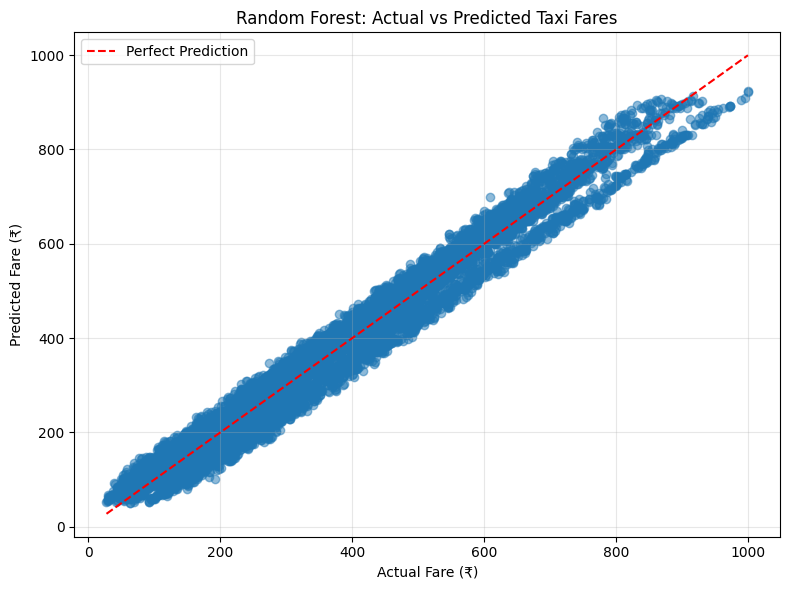

R² Score: 0.9725


In [84]:
# STEP 34: ACTUAL VS PREDICTED FARES

import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Train the final candidate model
final_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# Predict test-set fares
y_pred = final_model.predict(X_test)

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Fare (₹)')
plt.ylabel('Predicted Fare (₹)')
plt.title('Random Forest: Actual vs Predicted Taxi Fares')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("R² Score:", round(r2_score(y_test, y_pred), 4))

Step 35 — Feature Importance Analysis

Feature Importance:


,Feature,Importance
0,Distance_km,0.7426
2,Surge_Multiplier,0.2557
1,Trip_Duration,0.0016


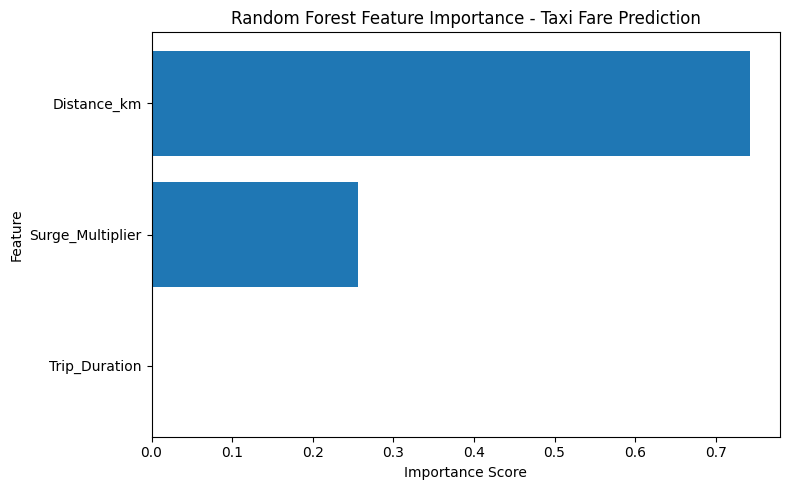

In [85]:
# STEP 35: FEATURE IMPORTANCE ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained Random Forest model
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': final_model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(importance_df.round(4))

# Visualize feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance - Taxi Fare Prediction')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Step 36 — Test the model on a new ride

In [86]:
# STEP 36: PREDICT FARE FOR A NEW RIDE
import pandas as pd

# Example ride details
new_ride = pd.DataFrame({
    'Distance_km': [10.0],
    'Trip_Duration': [30],
    'Surge_Multiplier': [1.2]
})

# Predict fare
predicted_fare = final_model.predict(new_ride)[0]

print("NEW RIDE DETAILS")
print("----------------")
print("Distance:", new_ride['Distance_km'].iloc[0], "km")
print("Trip Duration:", new_ride['Trip_Duration'].iloc[0], "minutes")
print("Surge Multiplier:", new_ride['Surge_Multiplier'].iloc[0])

print("\nPredicted Taxi Fare: ₹", round(predicted_fare, 2))

NEW RIDE DETAILS
----------------
Distance: 10.0 km
Trip Duration: 30 minutes
Surge Multiplier: 1.2

Predicted Taxi Fare: ₹ 191.13


Step 37 — Save your trained model

In [87]:
# STEP 37: SAVE THE TRAINED MODEL

import joblib
from google.colab import files

# Save the trained model
model_filename = 'taxi_fare_random_forest.pkl'

joblib.dump(final_model, model_filename)

print("Model saved successfully:", model_filename)

# Download the model to your computer
files.download(model_filename)

Model saved successfully: taxi_fare_random_forest.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STEP 38: Verify that the saved model works

In [88]:
# STEP 38: LOAD AND TEST THE SAVED MODEL

import joblib
import pandas as pd

# Load the saved model
loaded_model = joblib.load('taxi_fare_random_forest.pkl')

# Prepare a new ride
test_ride = pd.DataFrame({
    'Distance_km': [10.0],
    'Trip_Duration': [30],
    'Surge_Multiplier': [1.2]
})

# Predict using the loaded model
prediction = loaded_model.predict(test_ride)[0]

print("Saved model loaded successfully!")
print("Test ride: 10 km, 30 minutes, surge multiplier 1.2")
print(f"Predicted fare: ₹{prediction:.2f}")

print("\nModel verification:")
print("Original model prediction:", round(final_model.predict(test_ride)[0], 2))
print("Loaded model prediction:  ", round(prediction, 2))

Saved model loaded successfully!
Test ride: 10 km, 30 minutes, surge multiplier 1.2
Predicted fare: ₹191.13

Model verification:
Original model prediction: 191.13
Loaded model prediction:   191.13


Step 39 — Final Project Evaluation

In [89]:
# STEP 39: FINAL MODEL EVALUATION SUMMARY

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Generate final predictions
final_predictions = loaded_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, final_predictions)
mse = mean_squared_error(y_test, final_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, final_predictions)

# Display summary
evaluation_summary = pd.DataFrame({
    'Evaluation Metric': [
        'Mean Absolute Error (MAE)',
        'Mean Squared Error (MSE)',
        'Root Mean Squared Error (RMSE)',
        'R² Score'
    ],
    'Result': [
        round(mae, 4),
        round(mse, 4),
        round(rmse, 4),
        round(r2, 4)
    ]
})

print("FINAL TAXI FARE PREDICTION MODEL EVALUATION")
print("=" * 48)
display(evaluation_summary)

print("\nFinal Model: Random Forest Regressor")
print("Dataset Size:", len(df), "rides")
print("Features Used:", ', '.join(X_test.columns))
print("Test Set Size:", len(X_test), "rides")
print("Example Predicted Fare: ₹191.13")

FINAL TAXI FARE PREDICTION MODEL EVALUATION


,Evaluation Metric,Result
0,Mean Absolute Error (MAE),26.0278
1,Mean Squared Error (MSE),1104.6409
2,Root Mean Squared Error (RMSE),33.2361
3,R² Score,0.9725



Final Model: Random Forest Regressor
Dataset Size: 49230 rides
Features Used: Distance_km, Trip_Duration, Surge_Multiplier
Test Set Size: 9846 rides
Example Predicted Fare: ₹191.13


Step 40 — Write the final project conclusion

Conclusion

The Taxi Fare Prediction project demonstrates the application of data analysis, statistical techniques, and machine learning to estimate taxi fares. The dataset containing 49,230 rides was analyzed to understand the relationships between ride distance, trip duration, surge multiplier, and final fare.

The workflow included data preprocessing, exploratory data analysis, correlation analysis, statistical hypothesis testing, regression model development, model comparison, feature importance analysis, and prediction testing.

Five regression algorithms were compared: Linear Regression, Ridge Regression, Lasso Regression, Decision Tree, and Random Forest. Random Forest achieved the best performance in the final comparison without using Base_Fare as an input feature.

The final Random Forest model achieved an MAE of 26.0278, an RMSE of 33.2361, and an R² score of 0.9725 on the test set. Distance was the most important feature, followed by the surge multiplier. The trained model was saved and successfully reloaded, producing consistent predictions.

One important limitation is that the dataset’s Final_Fare is effectively calculated as Base_Fare multiplied by Surge_Multiplier. Therefore, the model evaluates its ability to approximate a synthetic fare-generation relationship and has not been validated on independently collected real-world taxi fares.

Overall, the project demonstrates a complete introductory machine learning workflow for regression-based fare estimation and provides a foundation for future improvements using real-world ride data and additional relevant features.

In [90]:
!pip install -q gradio

In [91]:
import gradio as gr
import pandas as pd
import numpy as np

In [92]:
import gradio as gr
import pandas as pd
import numpy as np

def predict_fare(distance, duration, surge):
    try:
        # Prepare input using the exact model features
        ride = pd.DataFrame({
            "Distance_km": [distance],
            "Trip_Duration": [duration],
            "Surge_Multiplier": [surge]
        })

        # Use your trained Random Forest model
        prediction = final_model.predict(ride)[0]

        return f"₹ {max(0, prediction):,.2f}"

    except Exception as e:
        return f"Error: {str(e)}"


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Taxi Fare Prediction"
) as demo:

    gr.Markdown("# 🚕 Taxi Fare Prediction")
    gr.Markdown("### AI-Powered Fare Estimation")
    gr.Markdown(
        "Enter your trip details to estimate the taxi fare."
    )

    with gr.Row():
        distance = gr.Slider(
            minimum=1,
            maximum=100,
            value=10,
            step=0.5,
            label="Trip Distance (km)"
        )

        duration = gr.Slider(
            minimum=1,
            maximum=180,
            value=30,
            step=1,
            label="Trip Duration (minutes)"
        )

        surge = gr.Slider(
            minimum=1,
            maximum=3,
            value=1.2,
            step=0.1,
            label="Surge Multiplier"
        )

    predict_button = gr.Button(
        "🚕 Predict Taxi Fare",
        variant="primary"
    )

    result = gr.Textbox(
        label="Estimated Taxi Fare",
        interactive=False
    )

    predict_button.click(
        fn=predict_fare,
        inputs=[distance, duration, surge],
        outputs=result
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8813e3d0938cb3fdf5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [93]:
from sklearn.metrics import r2_score, mean_absolute_error

# Predictions
train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

# R2 scores
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

# MAE
train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)

print("TRAINING PERFORMANCE")
print("R2 Score:", round(train_r2, 4))
print("MAE:", round(train_mae, 4))

print("\nTESTING PERFORMANCE")
print("R2 Score:", round(test_r2, 4))
print("MAE:", round(test_mae, 4))

print("\nR2 Gap:", round(train_r2 - test_r2, 4))

TRAINING PERFORMANCE
R2 Score: 0.9769
MAE: 23.7669

TESTING PERFORMANCE
R2 Score: 0.9725
MAE: 26.0278

R2 Gap: 0.0044
